In [151]:
import numpy as np
from utils import FordFulkerson, dag

np.random.seed(123)

# 1. Create and modify graph structure
G = dag([1, 2, 2, 1], seed=123, remove_fraction=0.0)
G.add_edges_from([(0, 1), (2, 1)])

# 2. Set capacities FIRST
for u, v, d in G.edges(data=True):
    if u == 0 or v == 5:
        d['capacity'] = 12
    else:
        d['capacity'] = np.random.randint(1, 3)

# 3. Instantiate solver and run
ff = FordFulkerson(G, sources=[0], sinks=[5])
flow = ff.run()

print(f'flow steps: {len(flow)}')

flow steps: 3


In [144]:

print(G.edges())


[(0, 2), (0, 1), (1, 3), (1, 4), (2, 3), (2, 4), (2, 1), (3, 5), (3, 4), (4, 5)]


Total Augmentation Iterations: 2

Step 1: Path = ['s', 0, 1, 4, 5, 't'], Delta = 1
Step 2: Path = ['s', 0, 2, 3, 5, 't'], Delta = 1


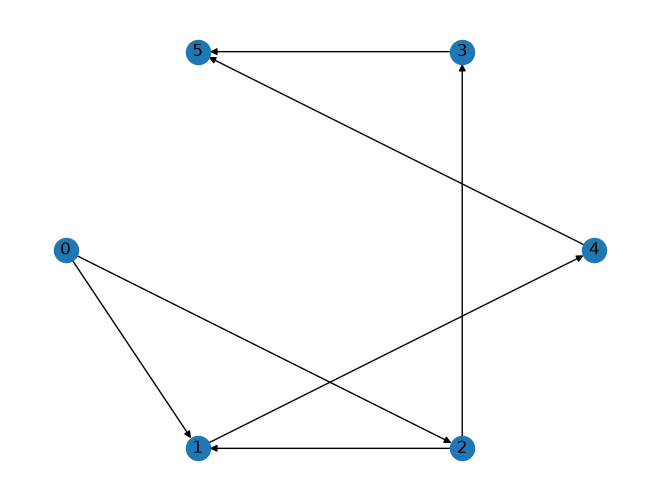

In [159]:
import numpy as np
import networkx as nx
from utils import FordFulkerson

import networkx as nx
from utils import FordFulkerson

def create_forced_4_step_graph():
    G = nx.DiGraph()
    
    # Capacities specifically engineered to force DFS onto the trap edge (1, 4)
    # Direct paths (1,3) and (2,4) are absent or limited so early paths fill (1,4).
    edges_with_capacities = [
        (0, 1, 2),  # Source capacity = 4
        (0, 2, 2),
        (1, 4, 2),  # Cross-edge (Trap edge: takes initial flow)
        (2, 1, 2),  # Back-edge access path
        (2, 3, 2),  # Bottleneck routes
        (3, 5, 2),  # Sink capacity = 4
        (4, 5, 2)
    ]
    
    for u, v, cap in edges_with_capacities:
        G.add_edge(u, v, capacity=cap)
        
    return G

# --- Execution ---
G = create_forced_4_step_graph()

ff = FordFulkerson(G, sources=[0], sinks=[5])
flow = ff.run()

steps = [s for s in flow if s.get('delta', 0) > 0]

print(f"Total Augmentation Iterations: {len(steps)}\n")
for i, step in enumerate(steps, 1):
    print(f"Step {i}: Path = {step['path']}, Delta = {step['delta']}")

nx.draw(G, pos=nx.shell_layout(G), with_labels=True)

In [166]:
import networkx as nx
from utils import FordFulkerson

def create_residual_reroute_graph():
    G = nx.DiGraph()
    
    # Node 0 (Source), Node 3 (Sink)
    # Layer 1: Node 1
    # Layer 2: Node 2
    
    # Capacities set to bottleneck single steps
    G.add_edge(0, 1, capacity=2)
    G.add_edge(0, 2, capacity=2)
    
    # Bridge Edge: Node 1 -> Node 2
    # DFS at Node 1 sees neighbor 2 before neighbor 3 (2 < 3)
    G.add_edge(1, 2, capacity=2)
    
    G.add_edge(1, 3, capacity=2)
    G.add_edge(2, 3, capacity=2)
    
    return G

# --- Execution ---
G = create_residual_reroute_graph()

ff = FordFulkerson(G, sources=[0], sinks=[3])
flow = ff.run()

steps = [s for s in flow if s.get('delta', 0) > 0]

print(f"Total Augmentation Iterations: {len(steps)}\n")
for i, step in enumerate(steps, 1):
    print(f"Step {i}: Path = {step['path']}, Delta = {step['delta']}")

Total Augmentation Iterations: 2

Step 1: Path = ['s', 0, 1, 3, 't'], Delta = 1
Step 2: Path = ['s', 0, 2, 3, 't'], Delta = 1


In [174]:
import networkx as nx
from utils import FordFulkerson

G = nx.DiGraph()
edge_capacity_dict = {(0,1): 2, (0,2):2, (1,2):2, (1,3):1, (2,3):2}
G.add_edges_from(edge_capacity_dict.keys())
nx.set_edge_attributes(G, edge_capacity_dict, 'capacity')

ff = FordFulkerson(G, sources=[0], sinks=[3])
flow = ff.run()

In [ ]:
path = flow[1]['path']
path[1:-2]
path[1:-2]
path[2:-1]

list(zip(path[1:-2],path[2:-1]))


[(0, 1), (1, 3)]